# SETONIX: MAUVE R-band M/L with three methods

**Created 2026-10-31. Targets: NGC4522 and NGC4698; separate 4800--7000 and 4800--8900 Angstrom runs.**

This notebook performs fresh pPXF SFH fits using the original nGIST per-bin fitting sequence, then compares `light_r`, the current `Mass.py` `light_norm_to_r`, and the unmodified native `sps.mass_to_light` helper on **the same fresh coefficients**. It also compares the actual original-nGIST template normalization with the independent reconstruction in `Mass.py`.

**Scope and limitation.** A direct pPXF refit is possible. What is unavailable in the inspected resources is a matching, independently supplied SSP mass array. We therefore derive SSP masses from the adopted matching BaSTI/Chabrier table. All methods share its mass calibration; this is not an independent test of that calibration. We retain the project's spectra, rather than substituting the standard pPXF E-MILES download (a different IMF/isochrone configuration).

No cube photometry, `speclite`, final galaxy mass or cross-range bin matching is used. Bin medians are population summaries, **not luminosity-weighted galaxy-integrated M/L**. The existing 7000 and 8900 configurations also differ in MDEG, so differences between their deviation distributions are configuration sensitivity, not a controlled wavelength-only experiment.

## 1. Execution instructions and deliberate refit guard

Open this notebook in the production **ngistenv1308** container on an allocated Setonix CPU node. The initial configuration is a deterministic pilot with `RUN_REFITS=False`: Run All performs input/preparation/photometry checks but launches no spectral fits. After reviewing those checks, set `RUN_REFITS=True` for the pilot. Only after a satisfactory pilot, set `RUN_MODE="full"` for all bins. Existing successful checkpoints are reused only when their complete case fingerprint agrees.

Do not run the full experiment on a login node. A batch example is included at the end. Shared nGIST code, Mass.py, cubes and production FITS/HDF5 products are read-only inputs; all derived products go into this experiment's scratch directory.

In [ ]:
from pathlib import Path
import os
# Set before numpy/scipy imports. Each fitting worker uses one BLAS thread.
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[key] = "1"

RUN_REFITS = False
RUN_MODE = "pilot"                         # "pilot" or "full"
PILOT_BINS_PER_CASE = 9
N_WORKERS = min(8, int(os.environ.get("SLURM_CPUS_PER_TASK", "1")))
BATCH_SIZE = max(8, 2*N_WORKERS)
RETRY_FAILED = False                        # Failed bins remain labelled; opt in to retry.
PREPARATION_RTOL = 1e-10
GALAXIES = ("NGC4522", "NGC4698")
RUN_ROOTS = {
    "7000": Path("/scratch/pawsey1308/mauve/products/v3tk_v7.6.8_7000"),
    "8900": Path("/scratch/pawsey1308/mauve/products/v3tk_v7.6.8"),
}
HOME_DIR = Path("/home/rhuang")
NGIST_DIR = Path("/software/projects/pawsey1308/ngist")
WORK_DIR = Path("/software/projects/pawsey1308/ngist_supplementary_public/ngistTutorial")
SSP_DIR = WORK_DIR/"spectralTemplates/EMILES_baseFe_safe"
LSF_DIR = WORK_DIR/"configFiles"
MASS_FILE = HOME_DIR/"Mass.py"
TABLE_FILE = HOME_DIR/"BaSTI+Chabrier.dat"
NOTEBOOK_FILE = HOME_DIR/"20261031_SETONIX_MAUVE_ML_Three_Methods.ipynb"
OUTPUT_ROOT = Path("/scratch/pawsey1308/rhuang/mauve_ml_three_methods_20261031")
R_FILTER = "REST_FRAME/Johnson-Cousins_R.dat"
TABLE_MAG_SYSTEM = "Vega"
# Explicit operational photometric convention, not metadata inferred from the .dat file.
# None adopts pPXF's solar magnitude for the selected R response and system.
# Replace with the table publisher's exact solar R magnitude if independently documented.
TABLE_SOLAR_M_R = None
SSP_TO_LSUN_PER_ANGSTROM = 1.0
assert RUN_MODE in {"pilot", "full"}
assert SSP_TO_LSUN_PER_ANGSTROM > 0
assert N_WORKERS > 0

## 2. Imports, source isolation and provenance

Only the required definitions are extracted from `Mass.py`, avoiding its module-level cube-processing workflow. The actual original nGIST modules are imported from the configured checkout. Their preparation and fitting functions are called directly; this notebook does not replace the pPXF optimizer or native M/L formula.

Input hashes include complete binned spectra and fixed kinematics: first-time hashing may take time on shared storage. The original and current preparation source hashes are recorded separately. Checkpoint directories are separated by pilot/full and fingerprint, so pilot maps cannot be mistaken for complete maps.

In [ ]:
import ast, copy, csv, hashlib, inspect, json, re, sys, time, traceback, warnings
from contextlib import contextmanager
from types import SimpleNamespace
from unittest.mock import patch
import numpy as np
import scipy, astropy, h5py, yaml, pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits
from scipy.interpolate import interp1d
import ppxf as ppxf_package
from ppxf import sps_util, ppxf_util
from ppxf.ppxf_util import gaussian_filter1d, log_rebin
from joblib import Parallel, delayed
from IPython.display import display

sys.path.insert(0, str(NGIST_DIR))
from ngistPipeline.auxiliary import _auxiliary
from ngistPipeline.prepareTemplates import miles
from ngistPipeline.starFormationHistories import ppxf_sfh_wrapper as sfh

def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for b in iter(lambda: f.read(1024*1024), b""): h.update(b)
    return h.hexdigest()

def fingerprint(obj):
    return hashlib.sha256(json.dumps(obj, sort_keys=True, default=str).encode()).hexdigest()

def write_json(path, obj):
    path = Path(path)
    temp = path.with_suffix(path.suffix+".tmp")
    temp.write_text(json.dumps(obj, indent=2, default=str, allow_nan=False)+"\n")
    temp.replace(path)

def load_mass_helpers(path):
    names = {"sha256_file", "parse_template_filename_key", "_resource_path", "load_run_setup",
             "load_lsf", "build_template_norm_flux_lookup", "r_light_mass_to_light"}
    constants = {"NGIST_REVISION", "TEMPLATE_VELSCALE_RATIO", "_TEMPLATE_RE"}
    tree = ast.parse(Path(path).read_text())
    nodes = [n for n in tree.body if
             isinstance(n, ast.FunctionDef) and n.name in names or
             isinstance(n, ast.Assign) and any(isinstance(t, ast.Name) and t.id in constants for t in n.targets)]
    ns = dict(globals(), __file__=str(path))
    exec(compile(ast.Module(body=nodes, type_ignores=[]), str(path), "exec"), ns)
    assert names <= ns.keys()
    return SimpleNamespace(**{n: ns[n] for n in names})

mass = load_mass_helpers(MASS_FILE)
SOURCE_FILES = [MASS_FILE, TABLE_FILE, Path(miles.__file__), Path(_auxiliary.__file__),
                Path(sfh.__file__), Path(inspect.getsourcefile(sps_util.sps_lib)),
                Path(ppxf_util.__file__), Path(inspect.getsourcefile(sfh.ppxf)),
                Path(sps_util.__file__).parent/"sps_models/spectra_sun_vega.npz",
                Path(sps_util.__file__).parent/"examples/FILTER.RES.txt"]
SOURCE_HASHES = {str(p): file_hash(p) for p in SOURCE_FILES}
notebook_source = json.loads(NOTEBOOK_FILE.read_text())
SOURCE_HASHES["notebook_sources_only"] = fingerprint([
    (c["cell_type"],c["source"]) for c in notebook_source["cells"]])
VERSIONS = {"python": sys.version, "ppxf": ppxf_package.__version__, "numpy": np.__version__,
            "scipy": scipy.__version__, "astropy": astropy.__version__, "h5py": h5py.__version__}
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
print("Environment:", VERSIONS)
print("Fresh fits enabled:", RUN_REFITS, "mode:", RUN_MODE, "workers:", N_WORKERS)

## 3. Small deterministic checks before using science data

The normalization identity is $w'_j=w_jn'_j/n_j$: both coefficient representations must imply the same original population amplitude $w_j/n_j$. These small checks also verify magnitude-to-mass units, map masking and the sign of the reported percentage differences. They are implementation checks, not galaxy results.

In [ ]:
def table_ssp_masses(mag_r, ml_r, solar_mag_r):
    mag_r, ml_r = np.asarray(mag_r, float), np.asarray(ml_r, float)
    if not np.isfinite(mag_r).all() or not np.isfinite(ml_r).all() or np.any(ml_r <= 0):
        raise ValueError("Invalid SSP table magnitude or M/L")
    return ml_r * 10.**(-.4*(mag_r-float(solar_mag_r)))

def convert_coefficients(weights, old_norm, new_norm):
    old_norm, new_norm = np.asarray(old_norm), np.asarray(new_norm)
    if np.any(old_norm <= 0) or np.any(new_norm <= 0): raise ValueError("Nonpositive normalization")
    return np.asarray(weights)*new_norm/old_norm

def map_bins(binid, values):
    result = np.full(np.shape(binid), np.nan)
    valid = np.isfinite(binid) & (binid >= 0)
    ids = np.asarray(binid)[valid]
    if np.any(ids != np.rint(ids)): raise ValueError("Noninteger BINID")
    result[valid] = [values.get(int(i), np.nan) for i in ids]
    return result

def difference_summary(a, b, bin_ids):
    a, b, bin_ids = np.asarray(a), np.asarray(b), np.asarray(bin_ids)
    ok = np.isfinite(a) & np.isfinite(b) & (a > 0) & (b > 0)
    if not ok.any(): return {"n_valid": 0}
    delta = 100.*(a[ok]/b[ok]-1.)
    dex = np.log10(a[ok]/b[ok]); ids = bin_ids[ok]; worst = np.argmax(abs(delta))
    return dict(n_valid=int(ok.sum()), median_percent=float(np.median(delta)),
                p16_percent=float(np.percentile(delta, 16)), p84_percent=float(np.percentile(delta, 84)),
                p95_abs_percent=float(np.percentile(abs(delta), 95)),
                p99_abs_percent=float(np.percentile(abs(delta), 99)),
                max_abs_percent=float(abs(delta[worst])), max_signed_percent=float(delta[worst]),
                max_abs_percent_bin=int(ids[worst]), median_dex=float(np.median(dex)))

np.testing.assert_allclose(table_ssp_masses([4., 5.], [1., 2.], 4.5), [10**.2, 2*10**-.2])
np.testing.assert_allclose(convert_coefficients([.2,.8], [2.,4.], [7.,3.])/np.array([7.,3.]), [.1,.2])
assert difference_summary([.9,1.2], [1.,1.], [5,8])["max_abs_percent_bin"] == 8
print("Deterministic unit/normalization/statistic checks passed")

## 4. Read the matched table and full SSP spectra

Each spectrum is matched by age, metallicity and baseFe identity, never by an assumed filesystem order. A rectangular age/metallicity grid and one baseFe alpha value are required by this experiment's `sps_lib` packaging. Duplicate or missing identities stop execution.

**Explicit photometric assumptions:** the table R column is treated as absolute Vega-system Johnson--Cousins R, and the original E-MILES spectra as $L_\odot$/Angstrom on the table's population scale. The minimal FITS headers and table do not independently certify those conventions. The default solar R magnitude comes from pPXF's solar/Vega spectra and the selected response, unless an exact table-publisher value is entered above. This adopted convention is recorded, not presented as recovered metadata. The SSP photometry comparison below exposes scale/passband offsets; no per-SSP R renormalization is used to force agreement. An exact photometric equivalence claim requires the publisher's response/zero-point convention to match.

Masses are reconstructed as $M_j=\Upsilon_{R,j}^{table}10^{-0.4(M_{R,j}-M_{R,\odot})}$. The original spectra remain unchanged apart from the single declared physical-unit conversion.

In [ ]:
TABLE_NAMES = ("IMF slope MH Age U B V R I J H K UminusV BminusV VminusR VminusI "
               "VminusJ VminusH VminusK ML_U ML_B ML_V ML_R ML_I ML_J ML_H ML_K "
               "F439W F555W F675W F814W C439_555 C555_675 C555_814").split()
tab = np.genfromtxt(TABLE_FILE, names=TABLE_NAMES, dtype=None, encoding=None, skip_header=2)
phot = {}
for r in tab:
    if r["IMF"] != "Ch": continue
    key = (round(float(r["Age"]),2), round(float(r["MH"]),2))
    if key in phot: raise ValueError(f"Duplicate Chabrier table identity {key}")
    phot[key] = r
ssp_files = sorted(SSP_DIR.glob("*.fits"))
ssp_lookup = {}
for p in ssp_files:
    k = mass.parse_template_filename_key(p)
    if k in ssp_lookup: raise ValueError(f"Duplicate SSP identity {k}")
    ssp_lookup[k] = p
ages = np.array(sorted({k[0] for k in ssp_lookup}))
metals = np.array(sorted({k[1] for k in ssp_lookup}))
assert {k[2] for k in ssp_lookup} == {0.}
SPS_KEYS = [(float(a),float(z),0.) for a in ages for z in metals]
assert len(SPS_KEYS) == len(ssp_lookup)
native_solar_r = float(np.asarray(ppxf_util.mag_sun(R_FILTER, system=TABLE_MAG_SYSTEM)).item())
solar_r = native_solar_r if TABLE_SOLAR_M_R is None else float(TABLE_SOLAR_M_R)
mag_r = np.array([phot[k[:2]]["R"] for k in SPS_KEYS], float)
table_ml = np.array([phot[k[:2]]["ML_R"] for k in SPS_KEYS], float)
table_lum = 10.**(-.4*(mag_r-solar_r))
ssp_masses = table_ssp_masses(mag_r, table_ml, solar_r)
wave = None; spectra = []
for k in SPS_KEYS:
    with fits.open(ssp_lookup[k], memmap=True) as h:
        hdr = h[0].header
        x = hdr["CRVAL1"] + hdr["CDELT1"]*np.arange(hdr["NAXIS1"])
        if wave is None: wave = x
        np.testing.assert_array_equal(wave, x)
        spectra.append(np.asarray(h[0].data, float)*SSP_TO_LSUN_PER_ANGSTROM)
spectra = np.array(spectra).T.reshape(len(wave),len(ages),len(metals))
assert np.isfinite(spectra).all() and np.all(ssp_masses > 0)
library_manifest = {p.name:file_hash(p) for p in ssp_files}
SPS_MANIFEST = dict(source_hashes=SOURCE_HASHES, versions=VERSIONS, template_hashes=library_manifest,
                    filter=R_FILTER, table_mag_system=TABLE_MAG_SYSTEM, solar_mag_r=solar_r,
                    solar_convention="ppxf-derived" if TABLE_SOLAR_M_R is None else "explicit override",
                    spectral_unit_factor=SSP_TO_LSUN_PER_ANGSTROM,
                    assumptions="Table absolute Vega R; spectra Lsun/A on matching population scale; masses table-derived")
EXPERIMENT_ID = fingerprint(SPS_MANIFEST)[:16]
EXPERIMENT_DIR = OUTPUT_ROOT/EXPERIMENT_ID
EXPERIMENT_DIR.mkdir(exist_ok=True)
SPS_FILE = EXPERIMENT_DIR/"matched_sps_input.npz"
if not SPS_FILE.exists():
    np.savez_compressed(SPS_FILE, templates=spectra, masses=ssp_masses.reshape(len(ages),len(metals)),
                        ages=ages, metals=metals, lam=wave, fwhm=np.full(len(wave),2.51))
write_json(EXPERIMENT_DIR/"run_manifest.json", SPS_MANIFEST)
del spectra
print("Matched SSPs:", len(SPS_KEYS), "solar M_R:", solar_r, "experiment:", EXPERIMENT_DIR)

## 5. Native SPS object, filter coverage and transparent photometry caching

The SPS object retains full R-band wavelength coverage even for a fit ending at 7000 Angstrom. Its normalization need not equal nGIST's. We transform coefficients using the independently measured reference preparation factors: $w^{SPS}=w^{fit}n^{SPS}/n^{reference}$. No Mass.py factor enters the native reference.

The unmodified `sps.mass_to_light` helper normally repeats the same SSP and solar photometry for every bin. To avoid tens of thousands of identical integrations, a scoped cache returns independent copies of those two photometry results. The actual native M/L helper is still called for every mixture; no replacement M/L formula supplies the reference. A test compares cached and uncached native calls. The cache is removed on exit and rejects unexpected spectra or filters.

In [ ]:
sps = sps_util.sps_lib(SPS_FILE, 20.5, fwhm_gal=None, norm_range=None)
solar_file = Path(sps_util.__file__).parent/"sps_models/spectra_sun_vega.npz"
with np.load(solar_file) as a:
    solar_lam, solar_flux = a["lam"].copy(), a["flux_sun"].copy()
original_photometry = sps_util.util.synthetic_photometry
ssp_phot = original_photometry(sps.lam_temp_full, sps.templates_full, R_FILTER, redshift=0, quiet=True)
sun_phot = original_photometry(solar_lam, solar_flux, R_FILTER, redshift=0, quiet=True)
assert np.all(ssp_phot.ok) and np.all(sun_phot.ok), "R response is not fully covered"
assert np.isfinite(ssp_phot.flux).all() and np.all(ssp_phot.flux > 0)
response_wave,response = ppxf_util.read_filter(R_FILTER,Path(ppxf_util.__file__).parent/"examples/FILTER.RES.txt")
nonzero_wave = response_wave[response>0]
for x,spec,photometry in [(sps.lam_temp_full,sps.templates_full,ssp_phot),
                           (solar_lam,solar_flux,sun_phot)]:
    assert x[0] <= nonzero_wave.min() and x[-1] >= nonzero_wave.max(), "Incomplete nonzero R-filter support"
    kernel = np.interp(x,response_wave,response,left=0,right=0)*np.gradient(x)*x
    expected = (np.einsum("i,ijk->jk",kernel,spec,optimize=False) if spec.ndim==3
                else np.sum(kernel*spec))/kernel.sum()
    np.testing.assert_allclose(photometry.flux[0],expected,rtol=2e-12,atol=0)

@contextmanager
def native_photometry_cache():
    def cached(lam, spec, bands, redshift=0, quiet=True, **kw):
        if bands != R_FILTER or redshift != 0 or kw: raise ValueError("Unexpected photometry request")
        if spec is sps.templates_full and np.array_equal(lam,sps.lam_temp_full):
            return copy.deepcopy(ssp_phot)
        if np.array_equal(lam,solar_lam) and np.array_equal(spec,solar_flux):
            return copy.deepcopy(sun_phot)
        raise ValueError("Unexpected spectra passed to native photometry cache")
    with patch.object(sps_util.util, "synthetic_photometry", cached): yield

test_weights = np.ones(sps.flux.shape)
native_uncached = sps.mass_to_light(test_weights, band=R_FILTER, quiet=True)
with native_photometry_cache():
    native_cached = sps.mass_to_light(test_weights, band=R_FILTER, quiet=True)
np.testing.assert_allclose(native_cached,native_uncached,rtol=1e-13)
conv = 3.828e33/(4*np.pi*(3.085677581491367e19)**2)
synthetic_lum = (ssp_phot.flux[0]/sun_phot.flux[0]*conv*sps.flux).ravel()
ssp_diag = pd.DataFrame(dict(age=[k[0] for k in SPS_KEYS], metal=[k[1] for k in SPS_KEYS],
                            table_M_R=mag_r, mass=ssp_masses, table_ml=table_ml,
                            table_lum=table_lum, synthetic_lum=synthetic_lum,
                            synthetic_ml=ssp_masses/synthetic_lum,
                            luminosity_ratio=synthetic_lum/table_lum))
ssp_diag.to_csv(EXPERIMENT_DIR/"ssp_photometry_comparison.csv",index=False)
display(ssp_diag.describe())
ratio = synthetic_lum/table_lum
if np.median(ratio) < .5 or np.median(ratio) > 2:
    raise ValueError("Gross spectral/table luminosity-scale discrepancy: resolve units before fitting")
fig, ax = plt.subplots(1,2,figsize=(10,3.4))
ax[0].scatter(ssp_diag.age,ratio,s=8); ax[0].set_xscale("log")
ax[0].set(xlabel="SSP age [Gyr]",ylabel="Synthetic / table R luminosity")
ax[1].scatter(table_ml,ssp_diag.synthetic_ml,s=8)
ax[1].plot([table_ml.min(),table_ml.max()],[table_ml.min(),table_ml.max()],"k--")
ax[1].set(xlabel="Table SSP M/L_R",ylabel="Spectral SSP M/L_R (shared masses)")
fig.tight_layout(); fig.savefig(EXPERIMENT_DIR/"ssp_photometry.png",dpi=150); plt.show()

## 6. Independently prepare each actual fitting template grid

The original nGIST `prepareSpectralTemplateLibrary` is run once in LIGHT mode and once with its unnormalized branch to recover the actual pre-division spectra. Their means are the reference divisors. A separate call to the current Mass.py reconstruction must reproduce those means and normalized samples. Configuration paths are resolved explicitly to the shared tutorial resources; only paths are relocated, not science parameters.

The comparison is made in the actual original preparation grid order and cross-checked against the saved GRID. Fingerprints include bin spectra, kinematics, weights, BINID map, CONFIG, source code, photometric conventions and masks. Spectral arrays are read per fitting batch later, not loaded for every galaxy at once.

The Mass.py `log_rebin` calls are observed directly to retain their prepared spectra, without altering returned values. These are compared to the original nGIST unnormalized spectra and to its actual LIGHT-normalized templates. Thus the test checks both the normalization factors and the wavelength-by-wavelength prepared results, not only an algebraic identity using the same reference spectrum. Per-SSP maximum sample errors are saved with the divisor comparison.

In [ ]:
def grid_keys(logage, metal, alpha):
    return [(round(10**float(a),2),round(float(z),2),round(float(e),2))
            for a,z,e in zip(np.ravel(logage),np.ravel(metal),np.ravel(alpha))]

def prepare_case(galaxy, run):
    folder = RUN_ROOTS[run]/galaxy
    wp = folder/f"{galaxy}_sfh_weights.fits"
    config = yaml.safe_load((folder/"CONFIG").read_text())
    assert config["SFH"]["OPT_TEMP"] == "default"
    assert config["SFH"]["FIXED"] and config["SFH"]["MC_PPXF"] == 0
    assert not config["SFH"]["SPEC_EMICLEAN"]
    config["GENERAL"]["CONFIG_DIR"] = str(LSF_DIR)
    config["GENERAL"]["TEMPLATE_DIR"] = str(WORK_DIR/"spectralTemplates")
    config["GENERAL"]["OUTPUT"] = str(folder)
    config["SFH"]["PLOT"] = False
    with fits.open(wp) as h:
        saved_w = np.asarray(h[1].data["WEIGHTS"],float)
        saved_keys = grid_keys(h[2].data["LOGAGE"],h[2].data["METAL"],h[2].data["ALPHA"])
        setup = mass.load_run_setup(wp,h[1].header,HOME_DIR,lsf_dir=LSF_DIR)
    assert len(set(saved_keys)) == len(saved_keys)
    assert np.isfinite(saved_w).all() and np.all(saved_w >= 0)
    spec_file = folder/f"{galaxy}_bin_spectra.hdf5"
    kin_file = folder/f"{galaxy}_kin.fits"
    map_file = folder/f"{galaxy}_spatial_binning_maps.fits"
    with h5py.File(spec_file,"r") as f:
        loglam = f["LOGLAM"][:]
        select = np.flatnonzero((np.exp(loglam)>setup["lmin"]) & (np.exp(loglam)<setup["lmax"]))
        assert f["SPEC"].shape == f["ESPEC"].shape
        assert f["SPEC"].shape[1] == len(saved_w)
        assert float(f.attrs["VELSCALE"]) == setup["galaxy_velscale"]
    loglam = loglam[select]
    data_lsf,temp_lsf = _auxiliary.getLSF(config,"SFH")
    ref = miles.prepareSpectralTemplateLibrary(config,setup["lmin"],setup["lmax"],
             setup["template_velscale"],data_lsf,temp_lsf,"SFH",True)
    raw_config = copy.deepcopy(config); raw_config["SFH"]["NORM_TEMP"] = "UNNORMALIZED_VALIDATION_ONLY"
    raw = miles.prepareSpectralTemplateLibrary(raw_config,setup["lmin"],setup["lmax"],
             setup["template_velscale"],data_lsf,temp_lsf,"SFH",True)
    keys = grid_keys(ref[4],ref[5],ref[6])
    assert set(keys) == set(saved_keys) == set(SPS_KEYS)
    assert keys == grid_keys(raw[4],raw[5],raw[6])
    reference_norm = raw[0].reshape(raw[0].shape[0],-1).mean(0)
    light = ref[0].reshape(ref[0].shape[0],-1)
    np.testing.assert_allclose(raw[0].reshape(light.shape)/reference_norm,light,rtol=PREPARATION_RTOL,atol=1e-12)
    mdata,mtemp = mass.load_lsf(setup["data_lsf_path"],setup["template_lsf_path"],setup["redshift"])
    # Observe the actual Mass.py log_rebin outputs without changing its calculation.
    # Its implementation processes sorted SSP paths; check the complete identity list.
    captured = []
    mass_globals = mass.build_template_norm_flux_lookup.__globals__
    direct_log_rebin = mass_globals["log_rebin"]
    def observe_rebin(*args,**kwargs):
        result = direct_log_rebin(*args,**kwargs)
        captured.append((np.array(result[0],copy=True),np.array(result[1],copy=True)))
        return result
    with patch.dict(mass_globals,{"log_rebin":observe_rebin}):
        lookup,meta = mass.build_template_norm_flux_lookup(SSP_DIR,setup["lmin"],setup["lmax"],
                        lsf_data=mdata,lsf_templates=mtemp,template_velscale=setup["template_velscale"],grid_keys=keys)
    path_keys = [mass.parse_template_filename_key(p) for p in sorted(SSP_DIR.glob("*.fits"))]
    assert len(captured) == len(path_keys) and set(path_keys) == set(keys)
    by_key = dict(zip(path_keys,captured))
    for k in keys:
        np.testing.assert_allclose(by_key[k][1],ref[2],rtol=0,atol=1e-13)
    mass_prepared = np.column_stack([by_key[k][0] for k in keys])
    raw_prepared = raw[0].reshape(raw[0].shape[0],-1)
    mass_norm = np.array([lookup[k] for k in keys])
    rel = mass_norm/reference_norm-1.
    np.testing.assert_allclose(mass_norm,reference_norm,rtol=PREPARATION_RTOL,atol=0)
    np.testing.assert_allclose(mass_prepared,raw_prepared,rtol=PREPARATION_RTOL,atol=1e-12)
    np.testing.assert_allclose(mass_prepared/mass_norm,light,rtol=PREPARATION_RTOL,atol=1e-12)
    normalized_error = np.max(np.abs(mass_prepared/mass_norm-light),axis=0)
    raw_error = np.max(np.abs(mass_prepared-raw_prepared),axis=0)
    max_normalized_error = float(normalized_error.max())
    max_prepared_error = float(raw_error.max())
    with fits.open(kin_file) as h:
        nmom = int(config["KIN"]["MOM"])
        start = np.column_stack([h[1].data[n] for n in ["V","SIGMA","H3","H4","H5","H6"][:nmom]])
    assert len(start) == len(saved_w) and np.isfinite(start).all()
    with fits.open(map_file) as h: binid,header = h["BINID"].data.copy(),h["BINID"].header.copy()
    valid_ids = np.unique(binid[np.isfinite(binid)&(binid>=0)])
    assert np.all(valid_ids == np.rint(valid_ids)) and valid_ids.max() < len(saved_w)
    mask_names = {config["SFH"]["SPEC_MASK"],config["SFH"].get("SPEC_PREMASK",config["SFH"]["SPEC_MASK"])}
    masks = {str(LSF_DIR/n):file_hash(LSF_DIR/n) for n in mask_names}
    inputs = [folder/"CONFIG",wp,spec_file,kin_file,map_file,Path(setup["data_lsf_path"]),Path(setup["template_lsf_path"])]
    manifest = dict(experiment_id=EXPERIMENT_ID,galaxy=galaxy,run=run,versions=VERSIONS,
                    source_hashes=SOURCE_HASHES,input_hashes={str(p):file_hash(p) for p in inputs},
                    masks=masks,max_norm_relative_error=float(abs(rel).max()),
                    max_prepared_sample_abs_error=max_prepared_error,
                    max_normalized_sample_abs_error=max_normalized_error,preparation=meta,
                    run_mode=RUN_MODE,pilot_bins=PILOT_BINS_PER_CASE)
    case_id = fingerprint(manifest)[:16]
    target = EXPERIMENT_DIR/RUN_MODE/f"{galaxy}_{run}_{case_id}"
    target.mkdir(parents=True,exist_ok=True)
    write_json(target/"manifest.json",manifest)
    pd.DataFrame(dict(age=[k[0] for k in keys],metal=[k[1] for k in keys],
                     reference_norm=reference_norm,mass_norm=mass_norm,relative_error=rel,
                     max_prepared_sample_abs_error=raw_error,
                     max_normalized_sample_abs_error=normalized_error)).to_csv(
                     target/"template_preparation_comparison.csv",index=False)
    order = [SPS_KEYS.index(k) for k in keys]
    saved_order = [saved_keys.index(k) for k in keys]
    result = dict(galaxy=galaxy,run=run,folder=folder,out=target,manifest=manifest,
         config=config,setup=setup,templates=ref[0],loglam_template=ref[2],
         age_grid=ref[4],metal_grid=ref[5],alpha_grid=ref[6],keys=keys,
         reference_norm=reference_norm,mass_norm=mass_norm,order=order,
         ml=table_ml[order],lum=table_lum[order],saved_w=saved_w[:,saved_order],
         start=start,binid=binid,header=header,loglam=loglam,select=select,spec_file=spec_file)
    result["normalization_report"] = dict(
        galaxy=galaxy,fit_range=f"{setup['lmin']:.0f}-{setup['lmax']:.0f}",
        n_ssp=len(keys),n_prepared_pixels=int(light.shape[0]),n_spatial_bins=len(saved_w),
        galaxy_velscale=float(setup["galaxy_velscale"]),template_velscale=float(setup["template_velscale"]),
        max_abs_relative_norm_error=float(abs(rel).max()),
        median_abs_relative_norm_error=float(np.median(abs(rel))),
        max_abs_norm_error=float(abs(mass_norm-reference_norm).max()),
        max_abs_prepared_sample_error=max_prepared_error,
        max_abs_normalized_sample_error=max_normalized_error,
        normalization_rtol=float(PREPARATION_RTOL),sample_atol=1e-12,
        status="PASS",case_output=str(target))
    write_json(target/"normalization_reproduction.json",result["normalization_report"])
    print(galaxy,run,"bins",len(saved_w),"max normalization error",float(abs(rel).max()))
    return result

## 7. Fit worker: original multistep SFH routine and actual final pPXF object

Each worker calls the original `sfh.run_ppxf`. A temporary observer records the actual pPXF objects it returns internally; it does not change their arguments or results. The final object's coefficients must agree with the original wrapper's returned weights. The native helper later receives these actual fresh coefficients, expressed in its own normalization.

The original wrapper catches fit errors and returns NaNs. Those bins are explicitly marked failed here, not silently removed. Each batch is checkpointed after the parent process receives results. Failed checkpoints are not retried unless `RETRY_FAILED=True`. Only selected spectra are read from HDF5. No shared pipeline files are written.

In [ ]:
def fit_one(c, bin_id, galaxy_spec, galaxy_noise):
    from ngistPipeline.starFormationHistories import ppxf_sfh_wrapper as worker_sfh
    direct_ppxf = worker_sfh.ppxf
    observed = []
    def observe(*args,**kwargs):
        pp = direct_ppxf(*args,**kwargs)
        observed[:] = [pp]
        return pp
    cfg = c["config"]; g = c["loglam"]; setup = c["setup"]
    try:
        if not np.isfinite(galaxy_spec).all() or not np.isfinite(galaxy_noise).all() or np.any(galaxy_noise<=0):
            raise ValueError("Nonfinite spectrum or invalid spectral noise")
        premask = cfg["SFH"].get("SPEC_PREMASK",cfg["SFH"]["SPEC_MASK"])
        good0 = _auxiliary.spectralMasking(cfg,premask,g)
        good = _auxiliary.spectralMasking(cfg,cfg["SFH"]["SPEC_MASK"],g)
        regul = cfg["SFH"].get("REGUL")
        if regul is None:
            err = cfg["SFH"]["REGUL_ERR"]; regul = 0. if err == 0 else 1./err
        with patch.object(worker_sfh,"ppxf",observe):
            result = worker_sfh.run_ppxf(
                c["templates"],galaxy_spec.copy(),galaxy_noise.copy(),setup["galaxy_velscale"],
                c["start"][bin_id],good0,good,c["start"].shape[1],
                (c["loglam_template"][0]-g[0])*299792.458,-1,cfg["SFH"]["MDEG"],regul,
                cfg["SFH"]["DOCLEAN"],[True]*c["start"].shape[1],2,len(g),len(c["keys"]),
                len(c["saved_w"]),bin_id,c["templates"],.1,g,0,
                c["age_grid"],c["metal_grid"],c["alpha_grid"],cfg,False)
        w = np.asarray(result[1],float).ravel()
        if w.shape != (len(c["keys"]),) or not np.isfinite(w).all() or np.any(w<0) or w.sum()<=0:
            raise RuntimeError("Original nGIST SFH wrapper returned a failed fit")
        pp = observed[-1]
        np.testing.assert_allclose(w,pp.weights/pp.weights.sum(),rtol=1e-12,atol=1e-14)
        return dict(bin_id=int(bin_id),status="ok",weights=w,bestfit=np.asarray(result[2]),
                    mask=np.asarray(result[6]),chi2=float(result[8]),ebv=float(result[9]),
                    snr=float(result[7]),error="")
    except Exception:
        return dict(bin_id=int(bin_id),status="failed",error=traceback.format_exc())

def select_bins(c):
    n = len(c["saved_w"])
    if RUN_MODE == "full": return np.arange(n)
    proxy = (c["saved_w"]/c["saved_w"].sum(1)[:,None])@c["ml"]
    ranking = np.argsort(proxy,kind="stable")
    return np.unique(ranking[np.rint(np.linspace(0,n-1,min(PILOT_BINS_PER_CASE,n))).astype(int)])

def run_refits(c):
    selected = select_bins(c)
    np.savetxt(c["out"]/"selected_bin_ids.txt",selected,fmt="%d")
    checkpoint = c["out"]/"fit_results.hdf5"
    if not checkpoint.exists():
        with h5py.File(checkpoint,"w") as h:
            h.attrs["fingerprint"] = fingerprint(c["manifest"])
            n,p,k = len(c["saved_w"]),len(c["loglam"]),len(c["keys"])
            for name,shape in [("weights",(n,k)),("bestfit",(n,p)),("mask",(n,p))]:
                h.create_dataset(name,shape=shape,dtype="f8",chunks=(1,shape[1]),compression="gzip",fillvalue=np.nan)
            for name in ["chi2","ebv","snr"]: h.create_dataset(name,(n,),dtype="f8",fillvalue=np.nan)
            h.create_dataset("state",(n,),dtype="i1",fillvalue=0) # 0 pending, 1 ok, -1 failed
            h.create_dataset("error",(n,),dtype=h5py.string_dtype())
    with h5py.File(checkpoint,"r") as h:
        assert h.attrs["fingerprint"] == fingerprint(c["manifest"])
        state = h["state"][:]
    pending = selected[(state[selected]==0)|((state[selected]<0)&RETRY_FAILED)]
    worker_keys = ["config","setup","templates","start","loglam","loglam_template","keys",
                   "age_grid","metal_grid","alpha_grid","saved_w"]
    worker_case = {k:c[k] for k in worker_keys}
    started = time.monotonic()
    for j in range(0,len(pending),BATCH_SIZE):
        ids = pending[j:j+BATCH_SIZE]
        with h5py.File(c["spec_file"],"r") as h:
            # HDF5 supports only one fancy index at once; take contiguous wavelength slice first.
            lo,hi = int(c["select"][0]),int(c["select"][-1])+1
            assert np.array_equal(c["select"],np.arange(lo,hi))
            ordered = np.sort(ids)
            spec = h["SPEC"][lo:hi,ordered]; noise = h["ESPEC"][lo:hi,ordered]
        results = Parallel(n_jobs=N_WORKERS,max_nbytes="10M",mmap_mode="r",temp_folder=str(c["out"]))(
            delayed(fit_one)(worker_case,int(i),spec[:,t],noise[:,t]) for t,i in enumerate(ordered))
        with h5py.File(checkpoint,"r+") as h:
            for r in results:
                i = r["bin_id"]
                if r["status"] == "ok":
                    for name in ["weights","bestfit","mask","chi2","ebv","snr"]: h[name][i] = r[name]
                    h["error"][i] = ""; h["state"][i] = 1
                else:
                    h["error"][i] = r["error"]; h["state"][i] = -1
            h.flush()
        print(c["galaxy"],c["run"],f"new attempts {min(j+BATCH_SIZE,len(pending))}/{len(pending)}",
              f"elapsed {(time.monotonic()-started)/60:.1f} min",flush=True)
    return checkpoint,selected

## 8. Three M/L calculations and diagnostic separation

All primary methods use the same fresh fit. `light_norm_to_r` uses the current extracted Mass.py helper with its reconstructed divisors. Native pPXF uses the measured original-preparation divisors and its own stored normalization. The physical-unit conversion is included in that coefficient transformation.

An additional **diagnostic algebra check**, not a fourth primary method, evaluates the table-based mass/light ratio using reference divisors. It should match the Mass.py result to numerical accuracy when the normalization matches. Native pPXF can retain an offset because its R luminosities are integrated from spectra, while its masses were derived from table photometry. This offset must be interpreted alongside the SSP photometry diagnostic.

Percent differences are signed as 100(A/B - 1); positive means A is larger. One bin is one sample, irrespective of its number of map pixels. The largest absolute difference and its signed value/bin ID are both retained.

In [ ]:
METHODS = ["ML_R_light_r","ML_R_light_norm_to_r","ML_R_ppxf_native"]
PAIRS = [(METHODS[0],METHODS[1]),(METHODS[1],METHODS[2]),(METHODS[0],METHODS[2])]

def analyze_case(c,checkpoint,selected):
    rows = []
    with h5py.File(checkpoint,"r") as h, native_photometry_cache():
        for i in selected:
            state = int(h["state"][i])
            row = dict(bin_id=int(i),status="ok" if state==1 else "failed" if state==-1 else "pending")
            if state != 1:
                row["error"] = h["error"].asstr()[i]; rows.append(row); continue
            w = h["weights"][i]
            corrected = float(mass.r_light_mass_to_light(w[None,:],c["ml"],c["lum"],c["mass_norm"])[0][0])
            simple = float(w@c["ml"]/w.sum())
            native_norm = sps.flux.ravel()[c["order"]]
            converted = convert_coefficients(w,c["reference_norm"]*SSP_TO_LSUN_PER_ANGSTROM,native_norm)
            native_w = np.empty(len(w)); native_w[c["order"]] = converted
            native = float(sps.mass_to_light(native_w.reshape(sps.flux.shape),band=R_FILTER,quiet=True))
            amplitude = w/c["reference_norm"]
            table_control = float(np.sum(amplitude*c["lum"]*c["ml"])/np.sum(amplitude*c["lum"]))
            np.testing.assert_allclose(corrected,table_control,rtol=max(1e-12,5*PREPARATION_RTOL))
            if not np.isfinite(native) or native<=0: raise ValueError(f"Invalid native M/L for bin {i}")
            saved = c["saved_w"][i]; saved = saved/saved.sum()
            row.update(ML_R_light_r=simple,ML_R_light_norm_to_r=corrected,ML_R_ppxf_native=native,
                       table_control=table_control,chi2=float(h["chi2"][i]),ebv=float(h["ebv"][i]),
                       snr=float(h["snr"][i]),saved_weights_L1=float(abs(w-saved).sum()))
            rows.append(row)
    frame = pd.DataFrame(rows)
    for method in METHODS:
        if method not in frame: frame[method] = np.nan
    for a,b in PAIRS:
        frame[f"pct_{a}_over_{b}"] = 100.*(frame[a]/frame[b]-1.)
        frame[f"dex_{a}_over_{b}"] = np.log10(frame[a]/frame[b])
    frame.to_csv(c["out"]/"bin_results.csv",index=False)
    summaries = {f"{a}_over_{b}":difference_summary(frame[a],frame[b],frame.bin_id) for a,b in PAIRS}
    summary = dict(galaxy=c["galaxy"],run=c["run"],mode=RUN_MODE,n_total_bins=len(c["saved_w"]),
                   n_selected=len(selected),n_success=int((frame.status=="ok").sum()),
                   n_failed=int((frame.status=="failed").sum()),pairs=summaries,
                   median_ml={m:float(frame[m].median()) if frame[m].notna().any() else None for m in METHODS})
    write_json(c["out"]/"summary.json",summary)
    hdus = [fits.PrimaryHDU()]
    hdus[0].header["GALAXY"] = c["galaxy"]; hdus[0].header["FITLMAX"] = int(c["run"])
    hdus[0].header["RUNMODE"] = RUN_MODE
    hdus[0].header["NSUCCESS"] = summary["n_success"]
    hdus[0].header["COMPLETE"] = bool(summary["n_success"] == len(c["saved_w"]))
    for name in METHODS+[f"pct_{a}_over_{b}" for a,b in PAIRS]:
        array = map_bins(c["binid"],dict(zip(frame.bin_id,frame[name])))
        hdr = c["header"].copy();hdr["BUNIT"] = "percent" if name.startswith("pct_") else "Msol/Lsol_R"
        hdus.append(fits.ImageHDU(array,header=hdr,name=name))
    fits.HDUList(hdus).writeto(c["out"]/"ml_comparison_maps.fits",overwrite=True)
    return frame,summary

## 9. Figures, extreme-bin diagnostics and interpretation

Maps use one M/L colour scale across the three methods within a case; signed percentage maps use symmetric scales. Pilot maps deliberately show only the selected bins and carry PILOT labels. Scatter and distribution panels count each fitted bin once.

For every pair's worst bin, save its observed spectrum, fresh fit, residual, fitted-pixel mask and dominant SSP contributions. Failed fits are tabulated rather than represented as valid low M/L. The historical-weight L1 diagnostic is reproducibility context; it is not a fourth M/L method or an uncertainty estimate.

In [ ]:
def plot_case(c,frame,summary,checkpoint):
    figdir = c["out"]/"figures";figdir.mkdir(exist_ok=True)
    good = frame[frame.status=="ok"]
    if good.empty: print("No successful fits to plot"); return
    title = f'{c["galaxy"]} {c["run"]} A | {RUN_MODE.upper()} | {len(good)}/{len(c["saved_w"])} bins'
    finite = good[METHODS].to_numpy();vmin,vmax = np.nanmin(finite),np.nanmax(finite)
    fig,axes = plt.subplots(2,3,figsize=(14,8),layout="constrained")
    for j,m in enumerate(METHODS):
        im = axes[0,j].imshow(map_bins(c["binid"],dict(zip(good.bin_id,good[m]))),origin="lower",
                              vmin=vmin,vmax=vmax,cmap="viridis",interpolation="nearest")
        axes[0,j].set_title(m);fig.colorbar(im,ax=axes[0,j],label="M/L_R [solar R units]")
    for j,(a,b) in enumerate(PAIRS):
        col = f"pct_{a}_over_{b}";v = good[col].to_numpy();lim = max(float(abs(v).max()),1e-8)
        im = axes[1,j].imshow(map_bins(c["binid"],dict(zip(good.bin_id,v))),origin="lower",
                              vmin=-lim,vmax=lim,cmap="RdBu_r",interpolation="nearest")
        axes[1,j].set_title(a.replace("ML_R_","")+" / "+b.replace("ML_R_",""))
        fig.colorbar(im,ax=axes[1,j],label="100(A/B - 1) [%]")
    fig.suptitle(title);fig.savefig(figdir/"maps.png",dpi=160);plt.show()
    fig,axes = plt.subplots(3,3,figsize=(13,11),layout="constrained")
    for j,(a,b) in enumerate(PAIRS):
        d = good[f"pct_{a}_over_{b}"]
        axes[0,j].scatter(good[b],good[a],s=5,alpha=.5)
        lo,hi = min(good[a].min(),good[b].min()),max(good[a].max(),good[b].max())
        axes[0,j].plot([lo,hi],[lo,hi],"k--");axes[0,j].set(xlabel=b,ylabel=a)
        axes[1,j].hist(d,bins=min(60,max(5,len(good)//2)));axes[1,j].set(xlabel="Signed difference [%]",ylabel="Bins")
        axes[2,j].scatter(good.ML_R_ppxf_native,abs(d),s=5,alpha=.5)
        axes[2,j].set(xlabel="Native R-band M/L",ylabel="Absolute difference [%]")
    fig.suptitle(title);fig.savefig(figdir/"comparisons.png",dpi=160);plt.show()
    worst_ids = sorted({s["max_abs_percent_bin"] for s in summary["pairs"].values() if s["n_valid"]})
    for i in worst_ids:
        with h5py.File(checkpoint,"r") as h:
            bestfit,mask,w = h["bestfit"][i],h["mask"][i]>0,h["weights"][i]
        with h5py.File(c["spec_file"],"r") as h: observed = h["SPEC"][:,i][c["select"]]
        wave_fit = np.exp(c["loglam"])
        fig,ax = plt.subplots(2,1,figsize=(12,6),layout="constrained")
        ax[0].plot(wave_fit,observed,lw=.6,label="Observed");ax[0].plot(wave_fit,bestfit,lw=.6,label="Fresh pPXF")
        ax[0].legend();ax[0].set_ylabel("Original binned spectral units")
        ax[1].plot(wave_fit,observed-bestfit,lw=.6)
        ax[1].scatter(wave_fit[~mask],(observed-bestfit)[~mask],s=2,color="0.7",label="Excluded")
        ax[1].set(xlabel="Wavelength [A]",ylabel="Residual");ax[1].legend()
        fig.suptitle(title+f" | extreme bin {i}");fig.savefig(figdir/f"bin_{i}_fit.png",dpi=150);plt.show()
        top = np.argsort(w)[-12:][::-1]
        contributions = pd.DataFrame(dict(age=[c["keys"][j][0] for j in top],metal=[c["keys"][j][1] for j in top],
                                          LIGHT_weight=w[top],SSP_ML_R=c["ml"][top]))
        contributions.to_csv(figdir/f"bin_{i}_dominant_ssps.csv",index=False)
        display(good[good.bin_id==i]);display(contributions)

## 10. Execute one case at a time

With the default guard, this cell runs preparation checks for all four cases and does not call any fitter. In pilot/full fitting mode, it prepares one case, fits/resumes it, calls the native M/L helper and saves results before moving on. Large template arrays are released between cases. Preparation failures stop execution; individual failed fits remain in the checkpoint and counts.

Review pilot timing before the full 51,609-bin experiment. No hard runtime prediction is supplied without measured fitting times. Interrupting the notebook leaves completed batches restartable; in-progress batch work may be repeated.

In [ ]:
CASE_RESULTS = []
PREPARATION_RESULTS = []
for run in ("7000","8900"):
    for galaxy in GALAXIES:
        case = prepare_case(galaxy,run)
        PREPARATION_RESULTS.append(case["normalization_report"])
        if RUN_REFITS:
            checkpoint,selected = run_refits(case)
            frame,summary = analyze_case(case,checkpoint,selected)
            plot_case(case,frame,summary,checkpoint)
            CASE_RESULTS.append(dict(summary=summary,out=str(case["out"])))
            display(pd.DataFrame(summary["pairs"]).T)
        else:
            print("PREPARATION ONLY: refitting disabled; output",case["out"])
        del case
        import gc
        gc.collect()

## 10a. Normalization reproduction: all four cases

This is a **preparation-only numerical reproduction test** for NGC4522 and NGC4698, separately at 7000 and 8900 Angstrom. It runs regardless of `RUN_REFITS`; no observed spectrum needs to be fitted. Each row covers all 477 SSPs used by that case, not merely a selected spatial bin.

The independent calculations are (1) the actual original nGIST preparation functions and (2) the functions extracted from the current `Mass.py`. For every SSP we compare the log-wavelength grid, prepared unnormalized spectral samples, mean divisor immediately before LIGHT normalization, and final normalized spectral samples. A passive observer records Mass.py's actual preparation output; it does not reimplement or replace the preparation.

The table reports the maximum and median $|n_j^{Mass.py}/n_j^{nGIST}-1|$, maximum absolute divisor difference, and maximum absolute differences in prepared/normalized samples. PASS requires all wavelength, divisor and spectral-array assertions to pass, using the stated tolerances. The absolute sample differences are in their respective raw-template or normalized units and are **not M/L differences**. The plots show signed divisor residuals for all SSPs; zero is displayed explicitly, and a symlog scale accommodates roundoff-level positive/negative residuals.

**Saved preparation snapshot:** when outputs are present below, they were generated on Setonix from the notebook's actual preparation code, with spectral refits disabled. Their UTC time, host, software/source hashes and data provenance accompany the saved JSON. These outputs establish reproduction for these four configurations and this software stack; they do not establish bitwise identity with every historical nGIST environment or constitute completed three-method galaxy M/L results.

Rerunning the preceding case loop refreshes this table and figure. Full SFH fits remain separately controlled by `RUN_REFITS`.

Preparation-only normalization reproduction | 2026-10-31T09:08:11.309623+00:00 | setonix-03
Rows cover every SSP in each case. No M/L or SFH-fit equivalence is inferred from this table.


,galaxy,fit_range,n_ssp,n_prepared_pixels,n_spatial_bins,max_abs_relative_norm_error,median_abs_relative_norm_error,max_abs_norm_error,max_abs_prepared_sample_error,max_abs_normalized_sample_error,status
0,NGC4522,4800-7000,477,6292,2582,7.6605e-15,1.5543e-15,9.1073e-18,0.0000e+00,0.0000e+00,PASS
1,NGC4698,4800-7000,477,6292,22547,6.8834e-15,1.8874e-15,8.6736e-18,0.0000e+00,0.0000e+00,PASS
2,NGC4522,4800-8900,477,9738,2593,9.1038e-15,1.9984e-15,9.1073e-18,0.0000e+00,0.0000e+00,PASS
3,NGC4698,4800-8900,477,9738,23887,8.8818e-15,1.9984e-15,8.4568e-18,0.0000e+00,0.0000e+00,PASS


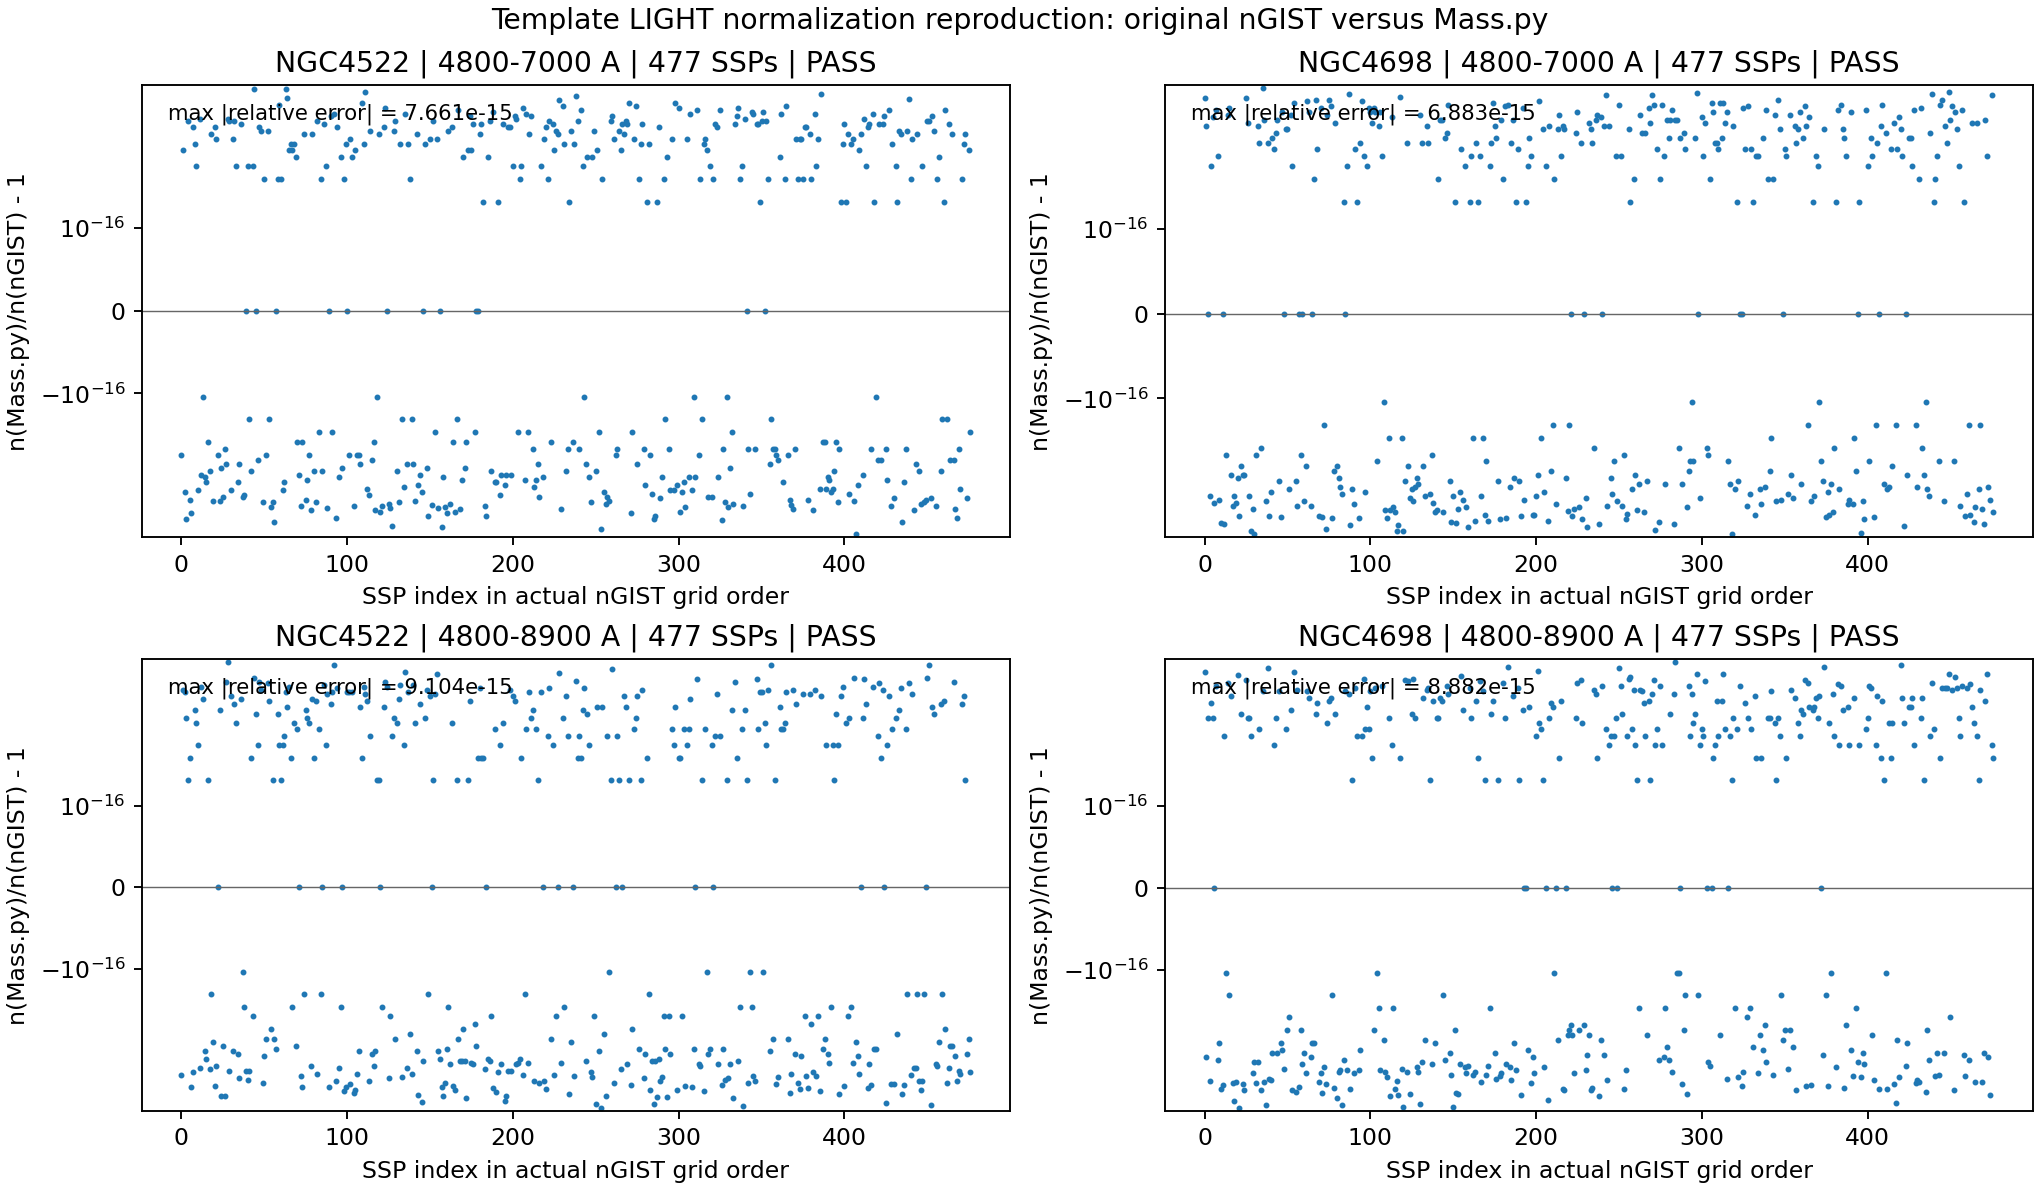

In [1]:
if not globals().get("PREPARATION_RESULTS"):
    print("Run the preparation case loop first; no normalization-reproduction results are available.")
else:
    import datetime, platform
    normalization_report = pd.DataFrame(PREPARATION_RESULTS)
    assert len(normalization_report) == len(GALAXIES)*len(RUN_ROOTS)
    assert (normalization_report.status == "PASS").all()
    assert (normalization_report.n_ssp == len(SPS_KEYS)).all()
    normalization_report.to_csv(EXPERIMENT_DIR/"normalization_reproduction_summary.csv",index=False)
    report_provenance = dict(
        generated_utc=datetime.datetime.now(datetime.timezone.utc).isoformat(),
        host=platform.node(),versions=VERSIONS,source_hashes=SOURCE_HASHES,
        refits_enabled=RUN_REFITS,validation_scope="Original nGIST versus current Mass.py preparation; all SSPs; four cases",
        cases=PREPARATION_RESULTS)
    write_json(EXPERIMENT_DIR/"normalization_reproduction_summary.json",report_provenance)
    print("Preparation-only normalization reproduction |",report_provenance["generated_utc"],"|",report_provenance["host"])
    print("Rows cover every SSP in each case. No M/L or SFH-fit equivalence is inferred from this table.")
    show_columns = ["galaxy","fit_range","n_ssp","n_prepared_pixels","n_spatial_bins",
        "max_abs_relative_norm_error","median_abs_relative_norm_error","max_abs_norm_error",
        "max_abs_prepared_sample_error","max_abs_normalized_sample_error","status"]
    display(normalization_report[show_columns].style.format({
        k:"{:.4e}" for k in show_columns if "error" in k}))
    fig,axes = plt.subplots(2,2,figsize=(12,7),layout="constrained")
    for ax,row in zip(axes.flat,PREPARATION_RESULTS):
        detail = pd.read_csv(Path(row["case_output"])/"template_preparation_comparison.csv")
        ax.plot(np.arange(len(detail)),detail.relative_error,".",ms=3)
        ax.axhline(0,color="0.4",lw=.6)
        ax.set_yscale("symlog",linthresh=1e-16)
        ax.set(xlabel="SSP index in actual nGIST grid order",ylabel="n(Mass.py)/n(nGIST) - 1",
               title=f'{row["galaxy"]} | {row["fit_range"]} A | {row["n_ssp"]} SSPs | {row["status"]}')
        ax.text(.03,.96,f'max |relative error| = {row["max_abs_relative_norm_error"]:.3e}',
                transform=ax.transAxes,va="top",fontsize=9)
    fig.suptitle("Template LIGHT normalization reproduction: original nGIST versus Mass.py")
    fig.savefig(EXPERIMENT_DIR/"normalization_reproduction_all_four.png",dpi=170)
    plt.show()


## 11. Compare disagreement summaries between fitting configurations

This is a comparison of the three-method disagreement distributions within each run, not a spatial cross-match between runs. Pilot results are labelled and cannot establish the sample maximum. Full-mode maxima apply only to successful fitted bins in these two galaxies, not the entire MAUVE sample. A high failure fraction limits conclusions and must be reported.

There are no p-values or bootstrap errors here: these are deterministic differences for fixed inputs and fitted mixtures. They are not estimates of SFH or M/L model uncertainty.

In [ ]:
if CASE_RESULTS:
    records = []
    for result in CASE_RESULTS:
        s = result["summary"]
        for pair,values in s["pairs"].items():
            records.append(dict(galaxy=s["galaxy"],run=s["run"],mode=s["mode"],pair=pair,
                                n_selected=s["n_selected"],n_success=s["n_success"],n_failed=s["n_failed"],**values))
    combined = pd.DataFrame(records)
    combined.to_csv(EXPERIMENT_DIR/f"all_cases_summary_{RUN_MODE}.csv",index=False)
    display(combined)
    fig,axes = plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
    for ax,metric in zip(axes,["p99_abs_percent","max_abs_percent"]):
        for (g,pair),group in combined.groupby(["galaxy","pair"]):
            ordered = group.sort_values("run")
            if metric not in ordered or not ordered[metric].notna().any(): continue
            ax.plot(ordered.run.astype(str),ordered[metric],marker="o",label=g+" "+pair.replace("ML_R_",""))
        ax.set(xlabel="Existing fitting-range configuration [A]",ylabel=metric.replace("_"," "))
        ax.set_title(RUN_MODE.upper())
    axes[-1].legend(fontsize=6);fig.savefig(EXPERIMENT_DIR/f"range_summary_{RUN_MODE}.png",dpi=160);plt.show()
else:
    print("No fresh fits requested. Preparation diagnostics exist; M/L results have not been generated.")

## 12. Reading the eventual results

1. **Preparation:** inspect the reference-versus-Mass.py normalization error before interpreting galaxy M/L differences. A failed preparation assertion is a failed reproduction check, not an astrophysical result.
2. **Incorrect R-light assumption:** `light_r / light_norm_to_r` measures the coefficient-interpretation difference for an identical fresh mixture.
3. **Native comparison:** `light_norm_to_r / ppxf_native` includes table-versus-synthetic R photometry and the explicitly adopted solar/passband convention. Use the SSP diagnostic and reference table-control identity to distinguish that baseline from normalization mistakes. Numerical identity is not assumed for different photometric implementations.
4. **Fitting reproducibility:** historical-weight differences can reflect software or fitting-environment drift. All primary three-way comparisons still use the same fresh coefficients.
5. **Range sensitivity:** compare robust and maximum deviations separately. Differences between 7000 and 8900 configurations also include their different polynomial degrees. Do not infer a wavelength-only cause.
6. **Mass calibration:** table-derived SSP masses are shared. Neither successful refits nor agreement validates the IMF, surviving-mass calibration or observational galaxy mass.

For every reported maximum, retain its bin ID, fit-quality values and diagnostic plot. Report failed counts and whether the run is PILOT or FULL.

## 13. Running on Setonix and output inventory

The kernel must be the production `/ngistenv1308/bin/python`, available through `ngistenv1308`. From an allocated node, open Jupyter using that environment or execute this notebook with its nbconvert installation. If batch execution reports a missing kernel, register a kernel backed by this interpreter in your writable Jupyter environment; do not fall back silently to the host Python.

An illustrative Slurm body (choose time/memory from the pilot, and first edit the notebook configuration to the desired mode):

```bash
#!/bin/bash -l
#SBATCH --account=pawsey1308
#SBATCH --partition=work
#SBATCH --nodes=1
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=8
#SBATCH --mem=64G
#SBATCH --time=12:00:00
set -euo pipefail
module load singularity/4.1.0-slurm
cd /home/rhuang
ngistenv1308 jupyter nbconvert --to notebook --execute \
  --ExecutePreprocessor.timeout=-1 \
  --ExecutePreprocessor.kernel_name=python3 \
  --output=20261031_SETONIX_MAUVE_ML_Three_Methods_executed.ipynb \
  20261031_SETONIX_MAUVE_ML_Three_Methods.ipynb
```

The 12-hour/64-GB values are starting requests, not a measured full-run requirement. The notebook's worker count respects the allocated CPU count. Checkpoints live under the experiment fingerprint and `pilot`/`full` subdirectories. Each case saves `manifest.json`, `template_preparation_comparison.csv`, `selected_bin_ids.txt`, `fit_results.hdf5`, `bin_results.csv`, `summary.json`, `ml_comparison_maps.fits` and figures. Shared outputs are the matched SPS NPZ, source/template manifest, SSP photometry diagnostic and combined range-summary CSV/figure.

**Delivery state:** code and structure validation are distinct from science execution. An unexecuted delivered notebook contains no measured galaxy results. Do not describe this notebook as a completed M/L validation until the corresponding preparation and fresh-fit outputs have actually been inspected.